We will test different edge algorithms on several sample images from the dogs and cats dataset

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [2]:
def run_edge(img: np.ndarray):
  gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
  sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
  sobel_mag = cv2.magnitude(sobel_x, sobel_y)
  sobel_mag = cv2.convertScaleAbs(sobel_mag)
  lap = cv2.convertScaleAbs(cv2.Laplacian(gray, cv2.CV_64F, ksize=3))
  canny_low = cv2.Canny(gray, 30, 100)
  canny_high = cv2.Canny(gray, 80, 180)

  return [
        ("Gray", gray),
        ("Sobel Magnitude", sobel_mag),
        ("Laplacian", lap),
        ("Canny 30/100", canny_low),
        ("Canny 80/180", canny_high),
    ]

In [3]:
def plot_images(images_data, title_category=""):
    num_images = len(images_data)
    cols = 3
    rows = (num_images + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(cols * 5, rows * 4))
    if num_images == 1:
        axes = np.array([axes])
    axes = axes.flatten()

    for i, (title, img) in enumerate(images_data):
        ax = axes[i]
        if len(img.shape) == 2 or img.shape[2] == 1:
            ax.imshow(img, cmap='gray')
        else:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{title_category}: {title}")
        ax.axis('off')

    for j in range(i + 1, len(axes)):
        axes[j].axis('off')

    plt.tight_layout()
    plt.show()

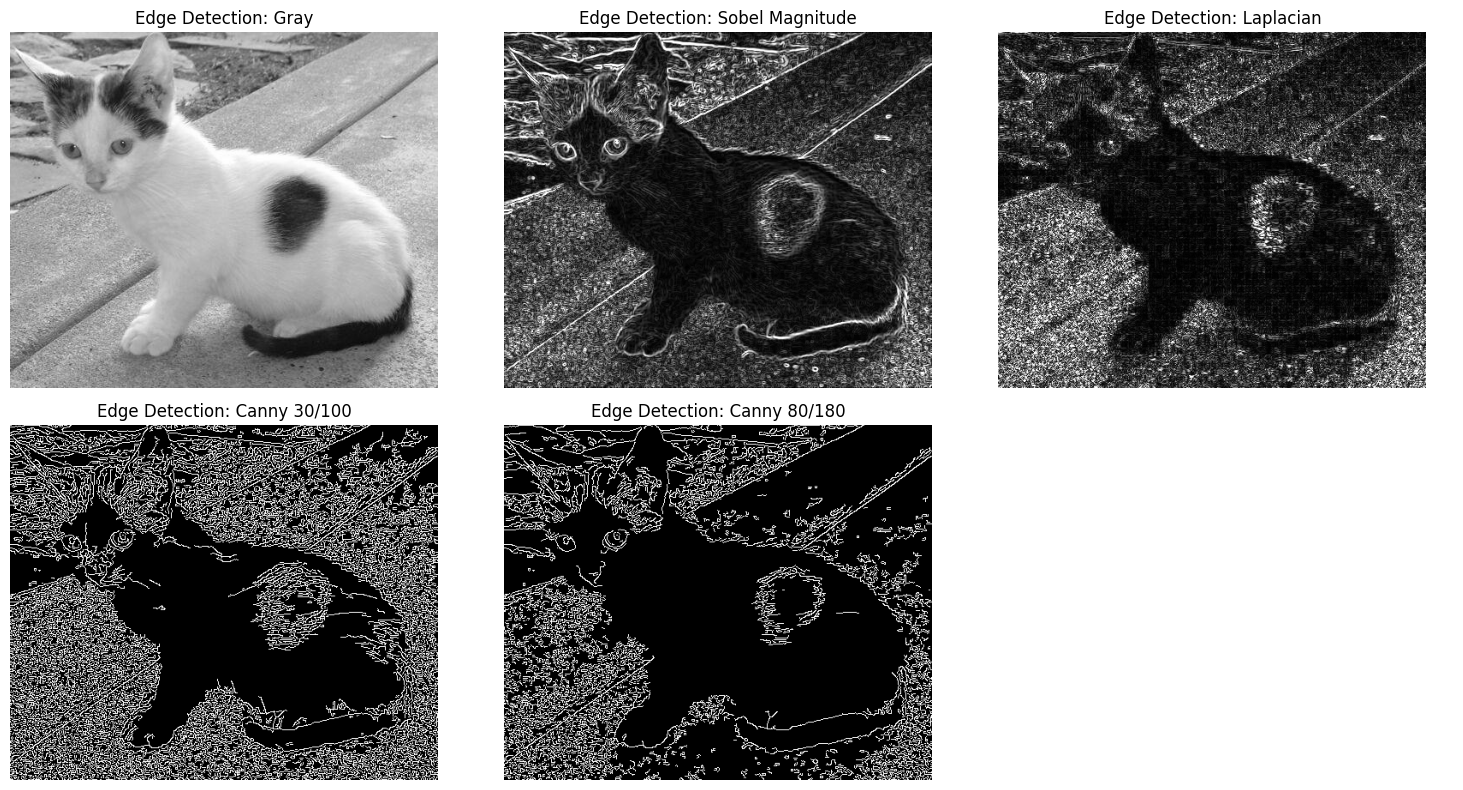

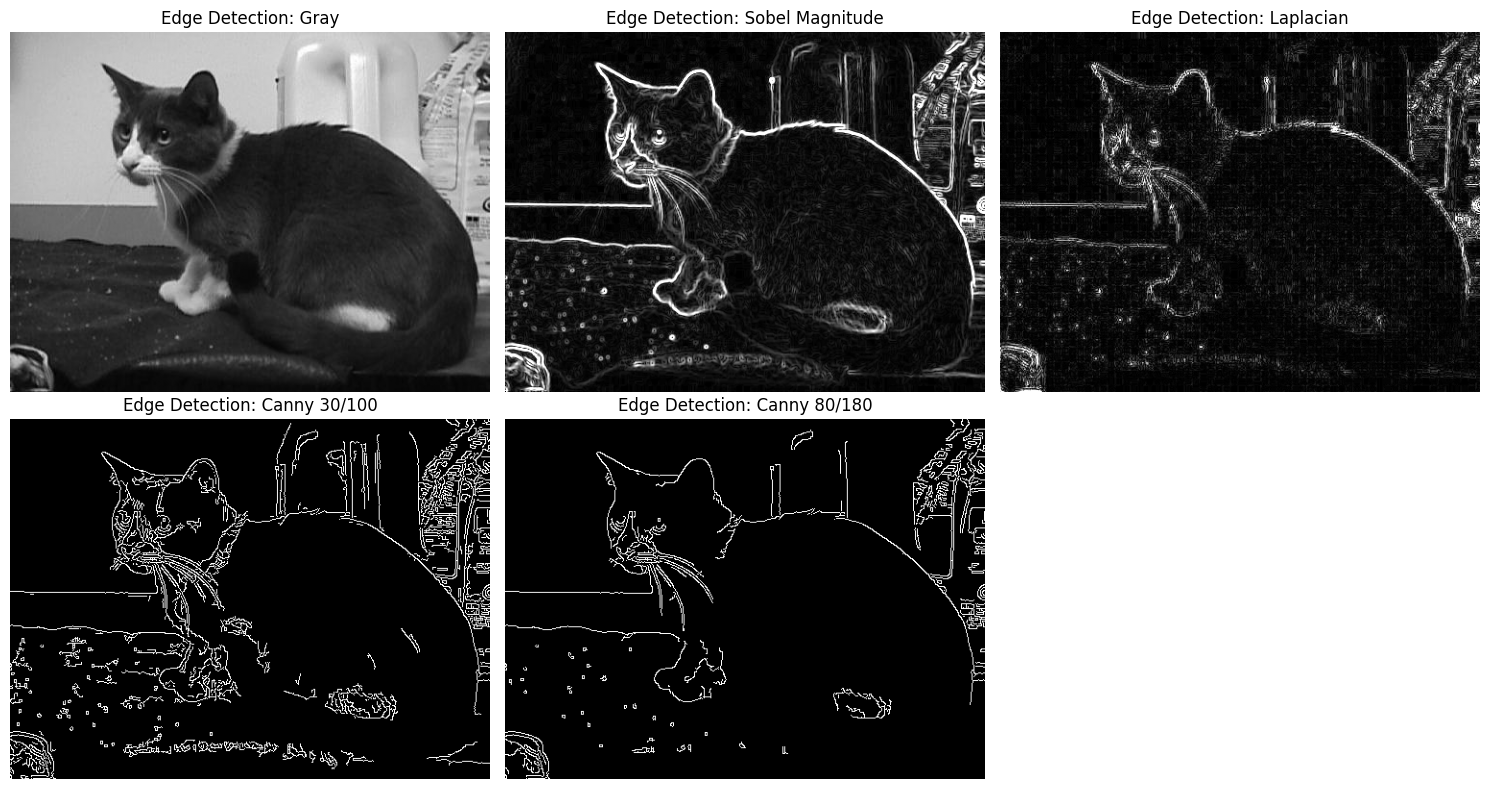

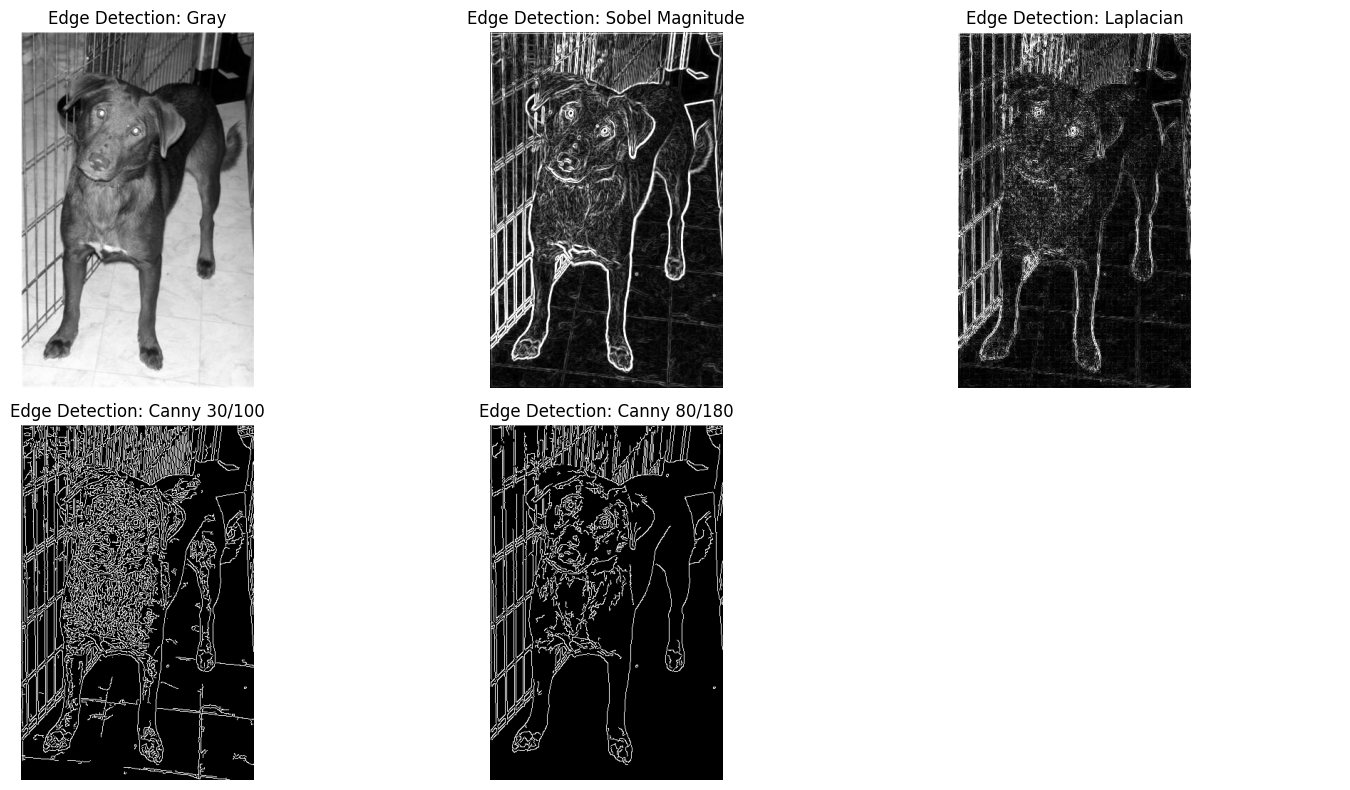

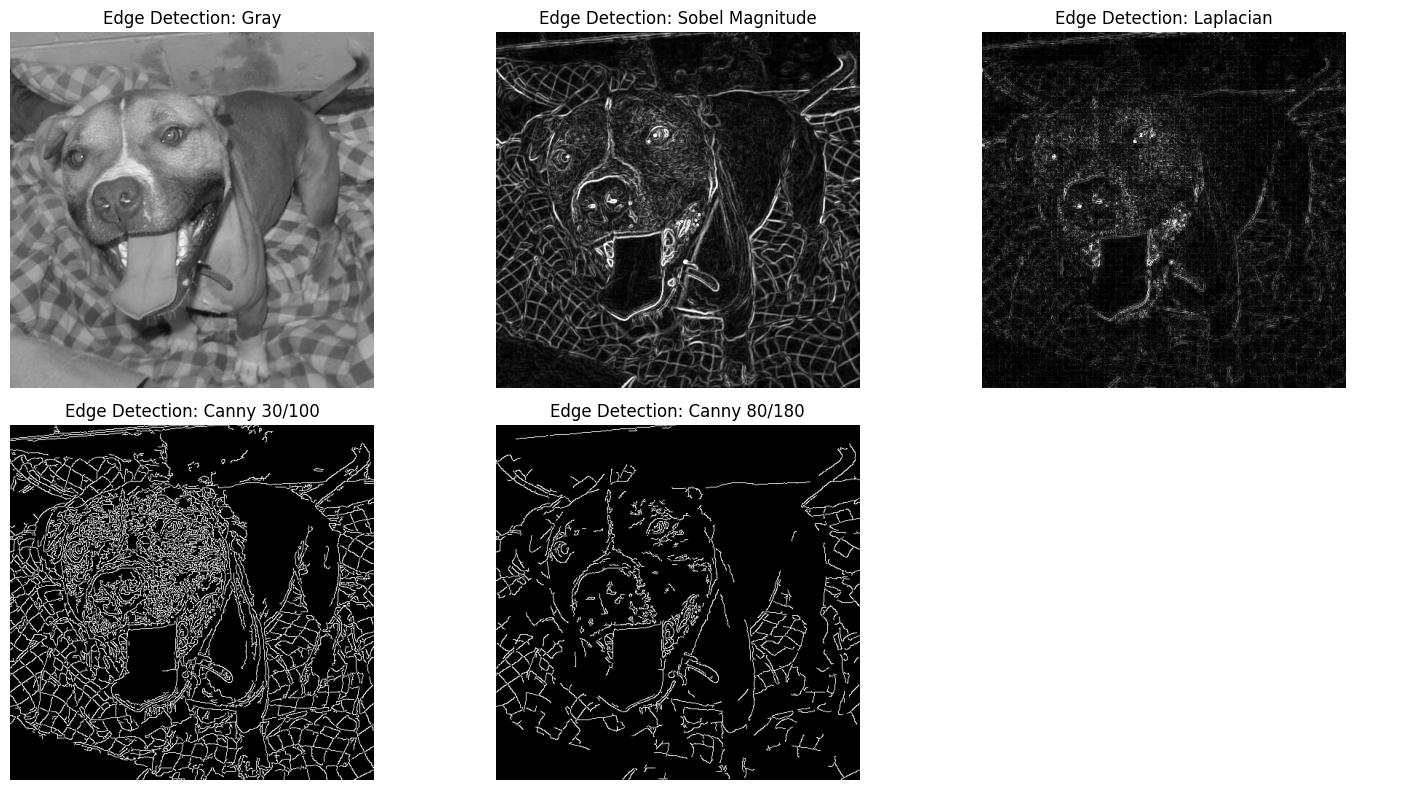

In [5]:
image_paths = ['cat_3.jpg', 'cat_4.jpg', 'dog_1.jpg', 'dog_6.jpg']
for img_path in image_paths:
  image = cv2.imread(img_path)
  rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
  gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
  edge = run_edge(image)
  plot_images(edge, title_category="Edge Detection")

There is no single best algorithm for detecting edges in an image. It depends on the task - is it a preprocerssing step for classification task (Canny or Laplacian)? is it for some sort of filling colors or painting (Canny)? is it just for art (Sobel magnitude)?

### Can edge algorithms help to build an efficient classifer?

Sure, they can as a preprocessing step to reduce the image complexity and to focus on the important parts (edges) that define the object shape.

### How can we measure the efficiency of edge detection algorithms?

In case we have ground truth edges, we can use binary metrics on pixels (Precision, Recall, F1-score, Jaccard Index).

In case we don't have: edge density (too high = noisy).

Running time and memory usage of the algorithm.